# Healthcare Insurance Cost Analysis
**Unit 1 – Data Analytics and Python for Data Preparation · Author: Adam**

I am a junior data analyst at a *fictional* health insurance company. Managers want to know **how medical charges change with age, BMI, smoking and region**.

This notebook goes step by step: **business case → load data → clean data → analyse → findings → evaluation**.
Run it with **Kernel → Restart & Run All**.

| Criterion | Section |
|---|---|
| 1.1, 1.2 | 1. Business case |
| 2.1, 2.3 | 2–5. ETL and analysis, 7. Tools and dashboard |
| 2.2 | 6. Code review |
| 3.1, 3.2 | 8. AI use and manager summary |
| 3.3 | 9. Evaluation |
| 4.1, 4.2 | 2. Data source, 3. Cleaning, 10. Data management |

# 1. Business Case (Task 1)

## 1.1 How data analytics is used in health insurance
These are examples from the industry, **not** results from my dataset.

| Application | What it does | Data needed | Decision it helps | Benefit | Limitation | Possible with my CSV? |
|---|---|---|---|---|---|---|
| **Cost comparison & expense estimation** | Compare costs between groups and estimate future costs | Member details, past claims, dates | How much money to budget for claims | Better budgets | The past may not predict the future | **Partly** – I can compare groups, but there are no dates |
| **Grouping people by risk** | Find groups (e.g. older smokers) for prevention programmes | Age, lifestyle, diagnoses | Where to offer stop-smoking or weight programmes | Help goes where it is needed | Needs sensitive medical data; risk of unfairness | **Partly** – I can group by age, BMI, smoking |
| **Fraud detection** | Flag unusual claims to check | Claim records, provider IDs, treatment codes | Which claims to investigate | Saves money | Can wrongly flag honest people | **No** – no claim-level data |
| **Treatment effectiveness** | Compare results and costs of treatments | Medical records and outcomes | Which treatments to fund | Better care per pound | Needs high-quality clinical data | **No** – no medical data |

## 1.2 The problem I am solving
- **Challenge:** managers use one overall average, which hides big differences between groups. They need to know which groups have higher charges to plan budgets.
- **Audience:** non-technical planning managers.
- **My questions:**
  - **Q1:** How do charges differ between smokers and non-smokers?
  - **Q2:** How are age and BMI linked to charges?
  - **Q3:** How do mean and median charges compare across regions – and does this still hold when smokers and non-smokers are looked at separately?
- **Role of analytics:** summaries and charts turn 1,338 rows into a few clear messages.
- **AI opportunity:** an AI model could estimate future costs for groups (checked against real results before being trusted), and an AI assistant can help write and check code and summaries.
- **Data challenges:** no ID column, no dates, currency not stated (data quality); people may confuse "linked to" with "caused by" (interpretability); health data is sensitive (privacy).

# 2. Data Source (Task 4.1)

| Item | Detail |
|---|---|
| Dataset | Healthcare Insurance – Kaggle: https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance |
| File | `data/raw/insurance.csv` (CSV format) |
| Type | **Secondary data** (collected by someone else). Originally from the book *Machine Learning with R* (Lantz, 2013), where it is described as **simulated** data – not real patients. |
| Access date | 09/11/2026 |
| Licence | Check the "License" field on the Kaggle page. Being public does not mean anyone can reuse it for anything. |
| Currency | Not stated – assumed US dollars (the regions are US regions). |

# 3. ETL – Extract, Transform, Load (Tasks 2.1, 2.3, 4.1)

## 3.1 Extract: load and look at the raw data

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

raw = pd.read_csv("data/raw/insurance.csv")
df = raw.copy()          # work on a copy so the raw data is never changed

print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (1338, 7)


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
print("Data types:")
print(raw.dtypes)
print("\nMissing values in each column:")
print(raw.isna().sum())

Data types:
age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

Missing values in each column:
age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64


In [3]:
print(raw["sex"].value_counts(), "\n")
print(raw["smoker"].value_counts(), "\n")
print(raw["region"].value_counts())

sex
male      676
female    662
Name: count, dtype: int64 

smoker
no     1064
yes     274
Name: count, dtype: int64 

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64


In [4]:
raw.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


**What I found:** 1,338 rows and 7 columns. **No missing values**, so I do not need to fill anything in. The categories are tidy (2 sexes, 2 smoker values, 4 regions) and the numbers look sensible (age 18–64, BMI 16–53).

## 3.2 Transform: check and clean the data

**Check 1 – Duplicate rows**

In [5]:
print("Duplicate rows:", df.duplicated().sum())
df[df.duplicated(keep=False)]

Duplicate rows: 1


,age,sex,bmi,children,smoker,region,charges
195,19,male,30.59,0,no,northwest,1639.5631
581,19,male,30.59,0,no,northwest,1639.5631


There is **one** exact duplicate. There is no ID column, so it *could* be two different people – but every value matches, even the charge to 4 decimal places, so it is very likely a copy. I remove it. Removing it changes the mean by less than 0.1%, so it does not affect my results.

In [6]:
rows_before = len(df)
df = df.drop_duplicates()
print("Rows before:", rows_before, "| rows after:", len(df))

Rows before: 1338 | rows after: 1337


**Check 2 – Tidy the text** (remove spaces, make lower case) so that "Male" and "male" would count as the same. Here nothing changes, but the check is still worth doing.

In [7]:
for column in ["sex", "smoker", "region"]:
    df[column] = df[column].str.strip().str.lower()
print(df["region"].unique())

<ArrowStringArray>
['southwest', 'southeast', 'northwest', 'northeast']
Length: 4, dtype: str


**Check 3 – Impossible values.** My rules: age 18–100, BMI 10–80, children 0–15, charges above 0.

In [8]:
bad_rows = df[(df["age"] < 18) | (df["age"] > 100) |
              (df["bmi"] < 10) | (df["bmi"] > 80) |
              (df["children"] < 0) | (df["children"] > 15) |
              (df["charges"] <= 0)]
print("Rows breaking a rule:", len(bad_rows))

Rows breaking a rule: 0


**Check 4 – Outliers.** Very high charges are **real** (e.g. serious illness), so I count them but **keep** them. An unusual value is not automatically a mistake.

In [9]:
q1 = df["charges"].quantile(0.25)
q3 = df["charges"].quantile(0.75)
upper_limit = q3 + 1.5 * (q3 - q1)
high = df[df["charges"] > upper_limit]
print(f"People above {upper_limit:,.0f}: {len(high)}  (of these, smokers: {(high['smoker'] == 'yes').sum()})")

People above 34,525: 139  (of these, smokers: 136)


**New columns.** I add an **age band** and a **BMI category** (WHO groups) so managers can compare groups easily. I keep the text categories (e.g. "yes"/"no") readable – I do **not** turn them into numbers, because no calculation here needs that.

In [10]:
df["age_band"] = pd.cut(df["age"], bins=[17, 24, 34, 44, 54, 64],
                        labels=["18-24", "25-34", "35-44", "45-54", "55-64"])
df["bmi_category"] = pd.cut(df["bmi"], bins=[0, 18.5, 25, 30, 100], right=False,
                            labels=["Underweight", "Healthy", "Overweight", "Obese"])
print("Rows without an age band:", df["age_band"].isna().sum())
df.head()

Rows without an age band: 0


,age,sex,bmi,children,smoker,region,charges,age_band,bmi_category
0,19,female,27.900,0,yes,southwest,16884.92400,18-24,Overweight
1,18,male,33.770,1,no,southeast,1725.55230,18-24,Obese
2,28,male,33.000,3,no,southeast,4449.46200,25-34,Obese
3,33,male,22.705,0,no,northwest,21984.47061,25-34,Healthy
4,32,male,28.880,0,no,northwest,3866.85520,25-34,Overweight


## 3.3 Load: save the clean data, reload it and check it

In [11]:
df.to_csv("data/clean/insurance_clean.csv", index=False)

clean = pd.read_csv("data/clean/insurance_clean.csv")
print("Reloaded:", clean.shape)

# Automatic checks - if one fails, the notebook stops with an error
assert clean.isna().sum().sum() == 0, "There are missing values!"
assert clean.duplicated().sum() == 0, "There are duplicates!"
assert len(clean) == len(raw) - 1, "Row count is wrong!"
assert set(clean["smoker"]) == {"yes", "no"}
assert clean["charges"].min() > 0
print("All checks passed")

Reloaded: (1337, 9)
All checks passed


In [12]:
# Record of changes
change_log = pd.DataFrame({
    "step": ["Check missing values", "Remove duplicates", "Tidy text", "Check impossible values",
             "Check outliers", "Add age_band and bmi_category"],
    "rows removed": [0, 1, 0, 0, "0 (kept)", 0],
})
change_log

,step,rows removed
0,Check missing values,0
1,Remove duplicates,1
2,Tidy text,0
3,Check impossible values,0
4,Check outliers,0 (kept)
5,Add age_band and bmi_category,0


## 3.4 Data dictionary

| Column | Type | Meaning |
|---|---|---|
| `age` | whole number | Age in years (18–64) |
| `sex` | text | female / male |
| `bmi` | decimal | Body mass index (kg/m²) |
| `children` | whole number | Number of children covered by the insurance (0–5) |
| `smoker` | text | yes / no |
| `region` | text | northeast, northwest, southeast, southwest (USA) |
| `charges` | decimal | Medical costs billed (not the insurance price); currency assumed USD |
| `age_band` | category | **New** – age group, e.g. 18-24 |
| `bmi_category` | category | **New** – Underweight / Healthy / Overweight / Obese |

**Data flow:** `data/raw/insurance.csv` (never changed) → this notebook cleans it → `data/clean/insurance_clean.csv` → used by the dashboard `app.py`.

# 4. Analysis (Task 2.1)

From here I use the reloaded clean data. I wrote **one small reusable function** so I don't repeat the same code for every group.

In [13]:
df = clean


def summarise_by(data, column):
    # Count, mean and median charges for each group in a column
    return data.groupby(column)["charges"].agg(["count", "mean", "median"]).round(0)


# NumPy statistics for all charges
charges = df["charges"].to_numpy()
print("Mean:  ", round(np.mean(charges)))
print("Median:", round(np.median(charges)))
print("Std:   ", round(np.std(charges, ddof=1)))

Mean:   13279
Median: 9386
Std:    12110


## 4.1 How are charges spread out?

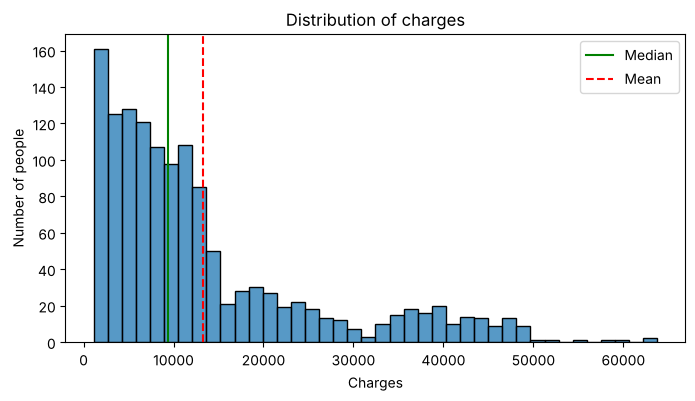

In [14]:
plt.figure(figsize=(8, 4))
sns.histplot(df["charges"], bins=40)
plt.axvline(df["charges"].median(), color="green", label="Median")
plt.axvline(df["charges"].mean(), color="red", linestyle="--", label="Mean")
plt.title("Distribution of charges")
plt.xlabel("Charges")
plt.ylabel("Number of people")
plt.legend()
plt.show()

**Finding:** the chart has a long tail to the right (**right-skewed**). Most people pay under 15,000, but some pay over 60,000. That is why the **mean (13,279) is higher than the median (9,386)**. The median is the better "typical" value.

## 4.2 Q1 – Smokers vs non-smokers

In [15]:
summarise_by(df, "smoker")

,count,mean,median
smoker,,,
no,1063,8441.0,7346.0
yes,274,32050.0,34456.0


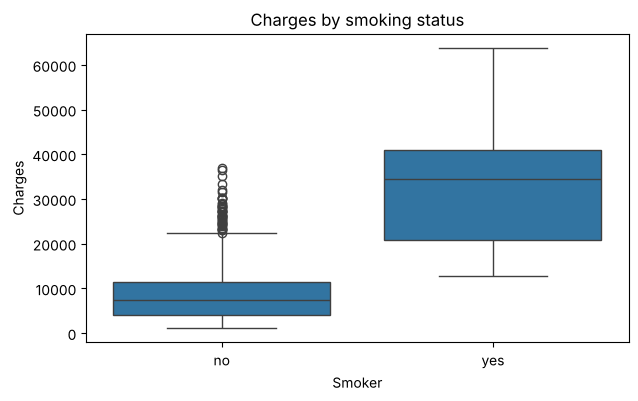

Smokers' median is 4.7 times higher


In [16]:
plt.figure(figsize=(7, 4))
sns.boxplot(data=df, x="smoker", y="charges", order=["no", "yes"])
plt.title("Charges by smoking status")
plt.xlabel("Smoker")
plt.ylabel("Charges")
plt.show()

smoker_median = df[df["smoker"] == "yes"]["charges"].median()
non_smoker_median = df[df["smoker"] == "no"]["charges"].median()
print(f"Smokers' median is {smoker_median / non_smoker_median:.1f} times higher")

In [17]:
# Filtering: smokers with BMI 30 or more vs smokers with lower BMI
smokers = df[df["smoker"] == "yes"]
print("Smokers BMI >= 30:", round(smokers[smokers["bmi"] >= 30]["charges"].median()))
print("Smokers BMI < 30: ", round(smokers[smokers["bmi"] < 30]["charges"].median()))

Smokers BMI >= 30: 40904
Smokers BMI < 30:  20167


**Q1 answer:** smokers (274 people) have a median charge of **34,456**; non-smokers (1,063 people) **7,346** – about **4.7 times higher**. The boxes barely overlap. Smokers with a BMI of 30+ have a median of **40,904**, double that of other smokers (20,167). Note there are far fewer smokers than non-smokers.

## 4.3 Q2 – Age and BMI

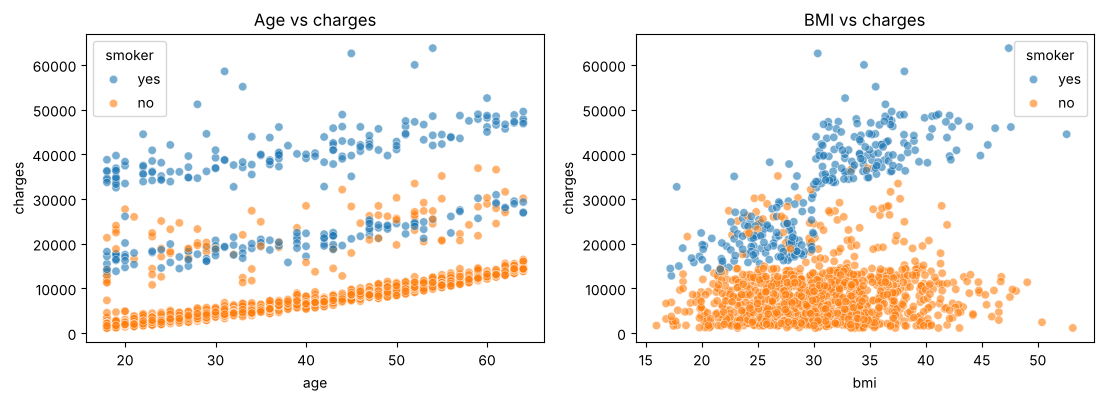

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(data=df, x="age", y="charges", hue="smoker", alpha=0.6, ax=axes[0])
axes[0].set_title("Age vs charges")
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.6, ax=axes[1])
axes[1].set_title("BMI vs charges")
plt.show()

In [19]:
summarise_by(df, "age_band")

,count,mean,median
age_band,,,
18-24,277,9038.0,2458.0
25-34,271,10352.0,4718.0
35-44,260,13134.0,7206.0
45-54,287,15854.0,10115.0
55-64,242,18513.0,13227.0


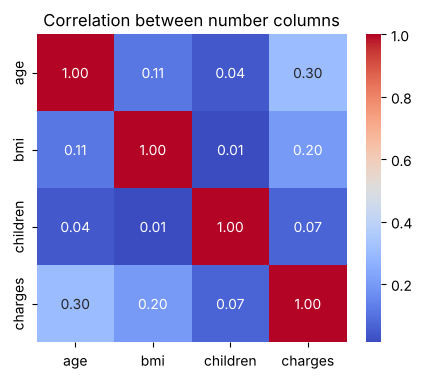

BMI vs charges, smokers:     0.81
BMI vs charges, non-smokers: 0.08


In [20]:
# Correlation - only real number columns (not text categories turned into codes)
plt.figure(figsize=(5, 4))
sns.heatmap(df[["age", "bmi", "children", "charges"]].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation between number columns")
plt.show()

print("BMI vs charges, smokers:    ", round(smokers["bmi"].corr(smokers["charges"]), 2))
non_smokers = df[df["smoker"] == "no"]
print("BMI vs charges, non-smokers:", round(non_smokers["bmi"].corr(non_smokers["charges"]), 2))

**Q2 answer:**
- **Age:** charges rise steadily – the median goes from **2,458** (18–24) to **13,227** (55–64). Correlation 0.30 (moderate).
- **BMI:** weak overall (0.20), but **strong for smokers (0.81)** and almost nothing for non-smokers (0.08).

⚠️ **Correlation is not causation** – two things moving together does not prove one causes the other.

## 4.4 Q3 – Regions

In [21]:
region_table = summarise_by(df, "region")
region_table["smokers %"] = (df.groupby("region")["smoker"].apply(lambda s: (s == "yes").mean() * 100)).round(1)
region_table

,count,mean,median,smokers %
region,,,,
northeast,324,13406.0,10058.0,20.7
northwest,324,12451.0,8977.0,17.9
southeast,364,14735.0,9294.0,25.0
southwest,325,12347.0,8799.0,17.8


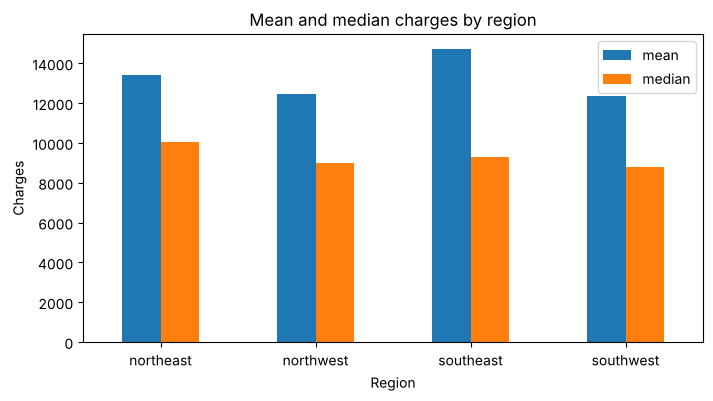

In [22]:
region_table[["mean", "median"]].plot(kind="bar", figsize=(8, 4))
plt.title("Mean and median charges by region")
plt.xlabel("Region")
plt.ylabel("Charges")
plt.xticks(rotation=0)
plt.show()

smoker         no      yes
region                    
northeast  8343.0  28101.0
northwest  7259.0  27489.0
southeast  6653.0  37484.0
southwest  7348.0  35165.0


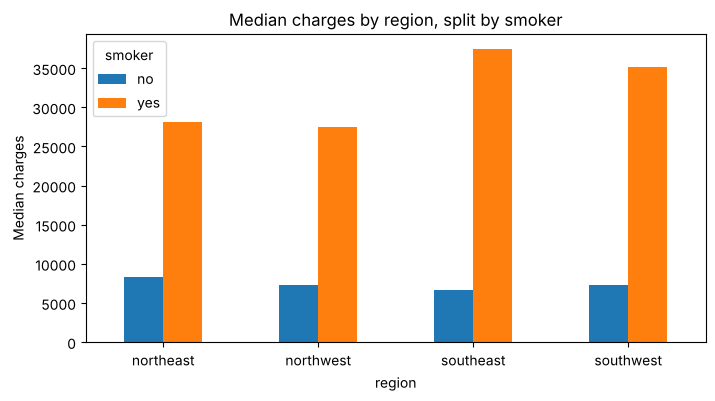

In [23]:
# Does the region difference stay when I look at smokers and non-smokers separately?
by_region_and_smoker = df.groupby(["region", "smoker"])["charges"].median().unstack().round(0)
print(by_region_and_smoker)
by_region_and_smoker.plot(kind="bar", figsize=(8, 4))
plt.title("Median charges by region, split by smoker")
plt.ylabel("Median charges")
plt.xticks(rotation=0)
plt.show()

**Q3 answer (partly answered):**
- The **southeast** has the highest mean (**14,735**) – but it also has the most smokers (**25%** vs about 18–21% elsewhere).
- When I split by smoking, **non-smokers in the southeast have the lowest median** (6,653).
- So the southeast looks expensive mostly because it has more smokers. This is called **confounding**: one factor (smoking) makes another (region) look important.
- I only have 4 broad region names, so I do not draw a map.

# 5. Summary of Findings
1. **Smoking** has the strongest link with charges (about 4.7× higher median).
2. Charges **rise with age**; **BMI** matters mainly for **smokers**.
3. **Region** differences are small and mostly linked to how many smokers live there.

# 6. Code Review – Before and After (Task 2.2)

I reviewed my code for correctness, clear names, comments and repeated code. Here are three improvements.

### Improvement 1 – Age bands lost all 18-year-olds (bug)
**Before:** `pd.cut(df["age"], bins=[18, 25, 35, 45, 55, 65])`. By default, `pd.cut` does **not** include the first edge, so everyone aged 18 got no band.

In [24]:
before = pd.cut(df["age"], bins=[18, 25, 35, 45, 55, 65])
print("BEFORE - people with no age band:", before.isna().sum())

after = pd.cut(df["age"], bins=[17, 24, 34, 44, 54, 64])
print("AFTER  - people with no age band:", after.isna().sum())
print("Check: total in bands =", after.value_counts().sum(), "= rows", len(df))

BEFORE - people with no age band: 69
AFTER  - people with no age band: 0
Check: total in bands = 1337 = rows 1337


**Why it matters:** 69 people would have silently disappeared from my age charts. I checked the fix by making sure the band counts add up to the total.

### Improvement 2 – Repeated code replaced with a function
**Before:** I wrote `df.groupby("smoker")["charges"].mean()` and `.median()` separately for each column, and forgot the group sizes. **After:** one function `summarise_by()` gives count, mean and median for any column.

In [25]:
before_mean = df.groupby("smoker")["charges"].mean().round(0)
after = summarise_by(df, "smoker")
print("Same means:", (before_mean == after["mean"]).all())
print("Counts add up to total:", after["count"].sum() == len(df))

Same means: True
Counts add up to total: True


### Improvement 3 – Removed category codes from the correlation heatmap
**Before:** I turned region into numbers (0, 1, 2, 3) and put it in the heatmap. That is wrong – "southwest = 3" is not a measurement. **After:** the heatmap uses only real number columns (age, bmi, children, charges), and regions are compared with group tables instead.

### Error handling
`app.py` uses `try/except` so that if the clean data file is missing, it shows a clear message instead of crashing.

### Version control (Git)
I used Git with **one commit per step** and clear messages, for example "Add data cleaning and analysis notebook". The raw data was committed first and never changed.

# 7. Tools and Dashboard (Task 2.3)

**Tools:** Python, pandas (tables), NumPy (maths), Matplotlib and seaborn (charts), Jupyter Notebook (this report), Streamlit (dashboard). All are listed in `requirements.txt` and installed with `pip install -r requirements.txt`.

**Dashboard (`app.py`):** run with `streamlit run app.py`. It loads the clean data and has:
- Filters for **age band, smoker and region**.
- Headline numbers (people, median, mean, % smokers).
- Tabs for each question, plus a manager summary.
- A warning if no people match the filters (instead of crashing).

**Dashboard testing record:**

| Test | Expected | Result |
|---|---|---|
| Open the dashboard | 1,337 people, median 9,386, mean 13,279 (same as notebook) | ✅ Pass |
| Open every tab | All charts show, no errors | ✅ Pass |
| Smoker = yes only | 274 people, 100% smokers | ✅ Pass |
| Region = southeast only | 364 people | ✅ Pass |
| Remove all regions | Warning message, no crash | ✅ Pass |
| Very small group | "Fewer than 30 people" note | ✅ Pass |

In [26]:
# Check the dashboard numbers match the notebook
print("All people:", len(df), "| median:", round(df["charges"].median()), "| mean:", round(df["charges"].mean()))
print("Smokers only:", len(df[df["smoker"] == "yes"]))
print("Southeast only:", len(df[df["region"] == "southeast"]))

All people: 1337 | median: 9386 | mean: 13279
Smokers only: 274
Southeast only: 364


# 8. Using AI (Tasks 3.1 and 3.2)

## 8.1 AI-use record
**Tool:** Claude (Anthropic) – an AI assistant that can write and run Python code, which makes it easy to test its suggestions. Only the public, anonymous dataset was used – no private health data.

| Task | What I asked | What the AI said | My decision |
|---|---|---|---|
| Cleaning | "Should I remove the one duplicate row?" | Remove it, but check the effect | **Accepted** – mean changes by less than 0.1% |
| Cleaning | "Should I remove very high charges as outliers?" | No, they are real | **Accepted** – kept them |
| Code review | "Check my age-band code for mistakes" | Pointed out that `pd.cut` leaves out the first edge, so 18-year-olds get no band | **Accepted** – fixed the bins and checked the counts (Section 6) |
| Charts | "Make charts clear for managers" | Add titles, labels, mean and median lines; also suggested a US map | **Accepted, but map rejected** – only 4 broad regions |
| Summary | Draft a manager summary | First draft (below) | **Changed** – some claims were wrong |

## 8.2 Manager summary with AI help
**Prompt:** *"Using my results, write a short summary for non-technical managers."*

**AI first draft:**
> "Smoking causes medical costs to rise: smokers cost around four times more. BMI drives up charges for everyone. The southeast is the most expensive region, so the company should increase its budget there."

**My checks:**

| Draft says | My analysis shows | What I changed |
|---|---|---|
| "Smoking **causes**…" | Data only shows a link | Changed to "is linked with" |
| "around four times" | Median ratio is 4.7 | Used the exact median ratio |
| "BMI drives up charges for everyone" | Strong for smokers (0.81), not non-smokers (0.08) | Corrected |
| "Southeast most expensive → bigger budget" | Mostly because of more smokers | Removed the recommendation |

**Final verified summary** (also in the dashboard's "Summary for managers" tab):
- Smoking has the strongest link with charges: smokers' median is **34,456** vs **7,346** for non-smokers – about **4.7 times higher**.
- Charges rise with age: median **2,458** (18–24) to **13,227** (55–64).
- BMI matters mainly for smokers: smokers with BMI 30+ have a median of **40,904**.
- Region differences are small: the southeast has the highest average (**14,735**) but also the most smokers (**25%**).
- These are associations, not causes, and must not be used for decisions about individual people.

# 9. Evaluation (Task 3.3)

**Did I answer my questions?**
- Q1 Smoking – **answered** clearly.
- Q2 Age and BMI – **answered**.
- Q3 Regions – **partly**: I can describe the differences, but not explain *why* (no data on local prices or health).

**Limitations:**
- The data is **simulated**, only ages 18–64 and 4 US regions.
- **No dates** – I cannot see trends over time.
- **No medical information** – I can say *who* costs more, not *why*.
- **Few smokers** (274) and only 20 underweight people – small groups are less reliable.
- **Confounding** – other hidden factors (income, job) may matter.
- **AI limits** – the AI draft contained wrong claims, so everything had to be checked.

**Alternatives I considered:**
| I chose | Alternative | Why |
|---|---|---|
| Median as "typical" value | Mean only | Charges are skewed; mean is pulled up by a few big values |
| Box plot for smokers | Bar chart of averages | Box plot also shows spread and outliers |
| CSV file | Database | CSV is simple and enough for 1,337 rows |

**What I learned:** always check patterns inside groups (the region result changed completely when I split by smoking), and always report the median for money data.

**Next step:** get data with dates and medical details to explain *why* costs differ.

# 10. Data Management (Tasks 4.1 and 4.2)

**Data quality checks:**
| Quality | Check | Result |
|---|---|---|
| Completeness | Missing values | 0 ✅ |
| Uniqueness | Duplicate rows | 1 found and removed ✅ |
| Consistency | Category values | All valid ✅ |
| Validity | Values in sensible ranges | All valid ✅ |
| Accuracy | Can't compare with original records | Cannot fully check |
| Timeliness | No dates in the data | Cannot check |

**Why I cleaned this way:** I didn't fill in missing values (there were none, and guessing health data would be wrong). I kept high charges because they are real.

**Storage:** raw data and clean data are in **separate folders**, so the raw data is never overwritten. CSV is fine for a small public file; real customer data would need a **database** with logins and access control.

**Privacy and ethics:**
- Health data is **special category data** under UK GDPR. This dataset has no names or IDs and is simulated, so the risk is low – but I still kept only the columns I needed.
- In a real company: limit who can access the data, share it securely, and delete it when no longer needed.
- **Public does not mean free to reuse** – follow the licence on Kaggle.
- **Bias:** using these results to price or refuse cover for one person would be unfair.

**Healthcare standards:** UK GDPR applies as good practice. Standards like **HL7 FHIR** (sharing health records) and **ICD-10** (diagnosis codes) do **not** apply here because there is no medical record data.

# 11. Conclusion
I took a raw CSV, checked and cleaned it, saved a clean copy, answered three business questions with charts, and built a dashboard for managers. **Smoking, age and (for smokers) BMI** are most strongly linked with higher charges; region matters much less than it first seems. These are links, not causes, and should only be used for group-level planning.

## References
- Kaggle – Healthcare Insurance dataset: https://www.kaggle.com/datasets/willianoliveiragibin/healthcare-insurance (accessed 9 Nov 2026)
- Lantz, B. (2013) *Machine Learning with R*. Packt.
- pandas documentation: https://pandas.pydata.org/docs/
- Streamlit documentation: https://docs.streamlit.io/
- ICO – Special category data (UK GDPR): https://ico.org.uk/

## AI acknowledgement
I used **Claude (Anthropic)** to help plan, write and debug code and draft the manager summary. I ran all the code and checked every number against my analysis (Section 8).